# Water Quality

### Preparação do ambiente

In [3]:
rm(list=ls())
options(digits=3)
library(repr)
library(readr)
library(corrplot)

In [4]:
grafdim <- function(x=11, y=9) { 
    options(repr.plot.width=x, repr.plot.height=y) 
}
exc <- function(antes, depois) { 
    print(paste("Excluídos:", (antes-depois), ", Restaram:", depois))
}

## Dados

Os dados são de [_Water Quality_](https://www.kaggle.com/datasets/adityakadiwal/water-potability), contendo observações com diversos valores para propriedades químicas da água com a finalidade de avaliar sua potabilidade: se é potável (`potability` = 1) ou não (`potability` = 0).

In [5]:
agua <- read.csv(unzip("/home/max/ref/d/dataset/Water_Quality/Water_Quality.zip","water_potability.csv"))
file.remove("water_potability.csv")

[1] TRUE

In [6]:
paste("Há ",nrow(agua)," registros no conjunto de dados")

[1] "Há  3276  registros no conjunto de dados"

In [7]:
str(agua)

'data.frame':	3276 obs. of  10 variables:
 $ ph             : num  NA 3.72 8.1 8.32 9.09 ...
 $ Hardness       : num  205 129 224 214 181 ...
 $ Solids         : num  20791 18630 19910 22018 17979 ...
 $ Chloramines    : num  7.3 6.64 9.28 8.06 6.55 ...
 $ Sulfate        : num  369 NA NA 357 310 ...
 $ Conductivity   : num  564 593 419 363 398 ...
 $ Organic_carbon : num  10.4 15.2 16.9 18.4 11.6 ...
 $ Trihalomethanes: num  87 56.3 66.4 100.3 32 ...
 $ Turbidity      : num  2.96 4.5 3.06 4.63 4.08 ...
 $ Potability     : int  0 0 0 0 0 0 0 0 0 0 ...


In [8]:
names(agua) <- c("ph","dureza","solido","cloramina","sulfato","condutividade",
                 "carbono_org","trihalometano","turbidez","potavel")

In [9]:
summary(agua)

       ph            dureza          solido        cloramina         sulfato   
 Min.   : 0.00   Min.   : 47.4   Min.   :  321   Min.   : 0.352   Min.   :129  
 1st Qu.: 6.09   1st Qu.:176.9   1st Qu.:15667   1st Qu.: 6.127   1st Qu.:308  
 Median : 7.04   Median :197.0   Median :20928   Median : 7.130   Median :333  
 Mean   : 7.08   Mean   :196.4   Mean   :22014   Mean   : 7.122   Mean   :334  
 3rd Qu.: 8.06   3rd Qu.:216.7   3rd Qu.:27333   3rd Qu.: 8.115   3rd Qu.:360  
 Max.   :14.00   Max.   :323.1   Max.   :61227   Max.   :13.127   Max.   :481  
 NAs    :491                                                      NAs    :781  
 condutividade  carbono_org   trihalometano        turbidez       potavel    
 Min.   :181   Min.   : 2.2   Min.   :  0.738   Min.   :1.45   Min.   :0.00  
 1st Qu.:366   1st Qu.:12.1   1st Qu.: 55.845   1st Qu.:3.44   1st Qu.:0.00  
 Median :422   Median :14.2   Median : 66.622   Median :3.96   Median :0.00  
 Mean   :426   Mean   :14.3   Mean   : 66.396   

In [10]:
round(sum(agua$potavel) / nrow(agua) * 100, 4)

[1] 39

Há NAs na variável resposta?

In [11]:
sum(is.na(agua$potavel))

[1] 0

Quantos registros há comprometidos por NAs?

In [12]:
naph <- is.na(agua$ph)
nasu <- is.na(agua$sulfato)
natr <- is.na(agua$trihalometano)
nall <- naph | nasu | natr
sum(nall)

[1] 1265

Quantas observações do grupo negativo estão comprometidas por NA?

In [13]:
sum(agua$potavel == 0 & nall)
round(sum(agua$potavel == 0 & nall) / sum(agua$potavel == 0) * 100, 2)

[1] 798

[1] 39.9

Quantas do grupo positivo?

In [14]:
sum(agua$potavel == 1 & nall)
round(sum(agua$potavel == 1 & nall) / sum(agua$potavel == 1) * 100, 2)

[1] 467

[1] 36.5

Reduzindo os NAs, diminuimos o _dataset_ à 61%:

In [15]:
ag <- agua[!nall,]
nrow(ag)
nrow(ag)/nrow(agua)

[1] 2011

[1] 0.614

In [16]:
summary(ag)

       ph             dureza          solido        cloramina        sulfato   
 Min.   : 0.227   Min.   : 73.5   Min.   :  321   Min.   : 1.39   Min.   :129  
 1st Qu.: 6.090   1st Qu.:176.7   1st Qu.:15616   1st Qu.: 6.14   1st Qu.:308  
 Median : 7.027   Median :197.2   Median :20934   Median : 7.14   Median :332  
 Mean   : 7.086   Mean   :196.0   Mean   :21917   Mean   : 7.13   Mean   :333  
 3rd Qu.: 8.053   3rd Qu.:216.4   3rd Qu.:27183   3rd Qu.: 8.11   3rd Qu.:359  
 Max.   :14.000   Max.   :317.3   Max.   :56489   Max.   :13.13   Max.   :481  
 condutividade  carbono_org   trihalometano       turbidez       potavel     
 Min.   :202   Min.   : 2.2   Min.   :  8.58   Min.   :1.45   Min.   :0.000  
 1st Qu.:367   1st Qu.:12.1   1st Qu.: 55.95   1st Qu.:3.44   1st Qu.:0.000  
 Median :423   Median :14.3   Median : 66.54   Median :3.97   Median :0.000  
 Mean   :427   Mean   :14.4   Mean   : 66.40   Mean   :3.97   Mean   :0.403  
 3rd Qu.:482   3rd Qu.:16.7   3rd Qu.: 77.29   3rd

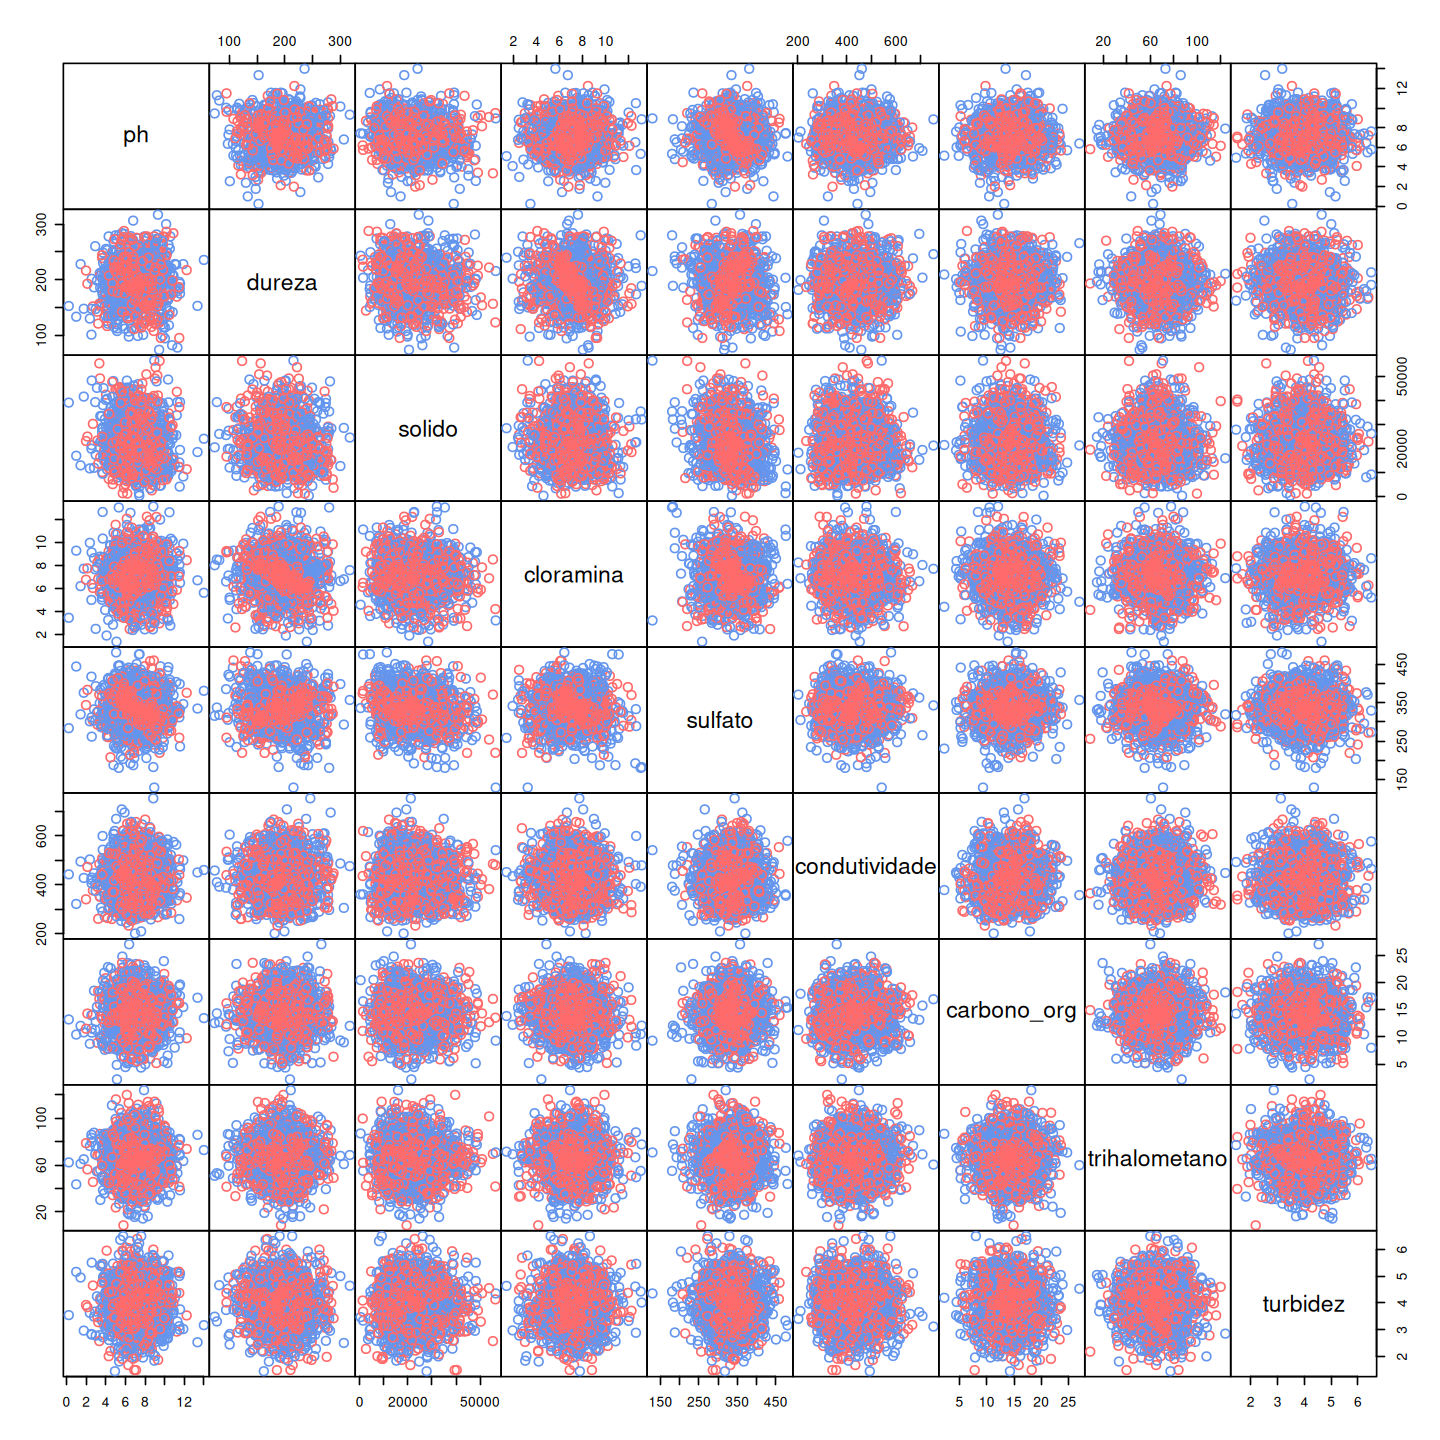

In [17]:
grafdim(12,12)
cores <- c("cornflowerblue","indianred1")
pairs(ag[,c(1:9)], col=cores[agua$potavel + 1], 
      cex=1.3, cex.labels=1.7, gap=0)

In [18]:
cor(ag[,c(1:9)])

,ph,dureza,solido,cloramina,sulfato,condutividade,carbono_org,trihalometano,turbidez
ph,1.0000,0.1089,-0.08761,-0.02477,0.01052,0.01413,0.02838,0.01828,-0.03585
dureza,0.1089,1.0000,-0.05327,-0.02268,-0.10852,0.01173,0.01322,-0.01540,-0.03483
solido,-0.0876,-0.0533,1.00000,-0.05179,-0.16277,-0.00520,-0.00548,-0.01567,0.01941
cloramina,-0.0248,-0.0227,-0.05179,1.00000,0.00625,-0.02828,-0.02381,0.01499,0.01314
sulfato,0.0105,-0.1085,-0.16277,0.00625,1.00000,-0.01619,0.02678,-0.02335,-0.00993
condutividade,0.0141,0.0117,-0.00520,-0.02828,-0.01619,1.00000,0.01565,0.00489,0.01249
carbono_org,0.0284,0.0132,-0.00548,-0.02381,0.02678,0.01565,1.00000,-0.00567,-0.01543
trihalometano,0.0183,-0.0154,-0.01567,0.01499,-0.02335,0.00489,-0.00567,1.00000,-0.02050
turbidez,-0.0358,-0.0348,0.01941,0.01314,-0.00993,0.01249,-0.01543,-0.02050,1.00000


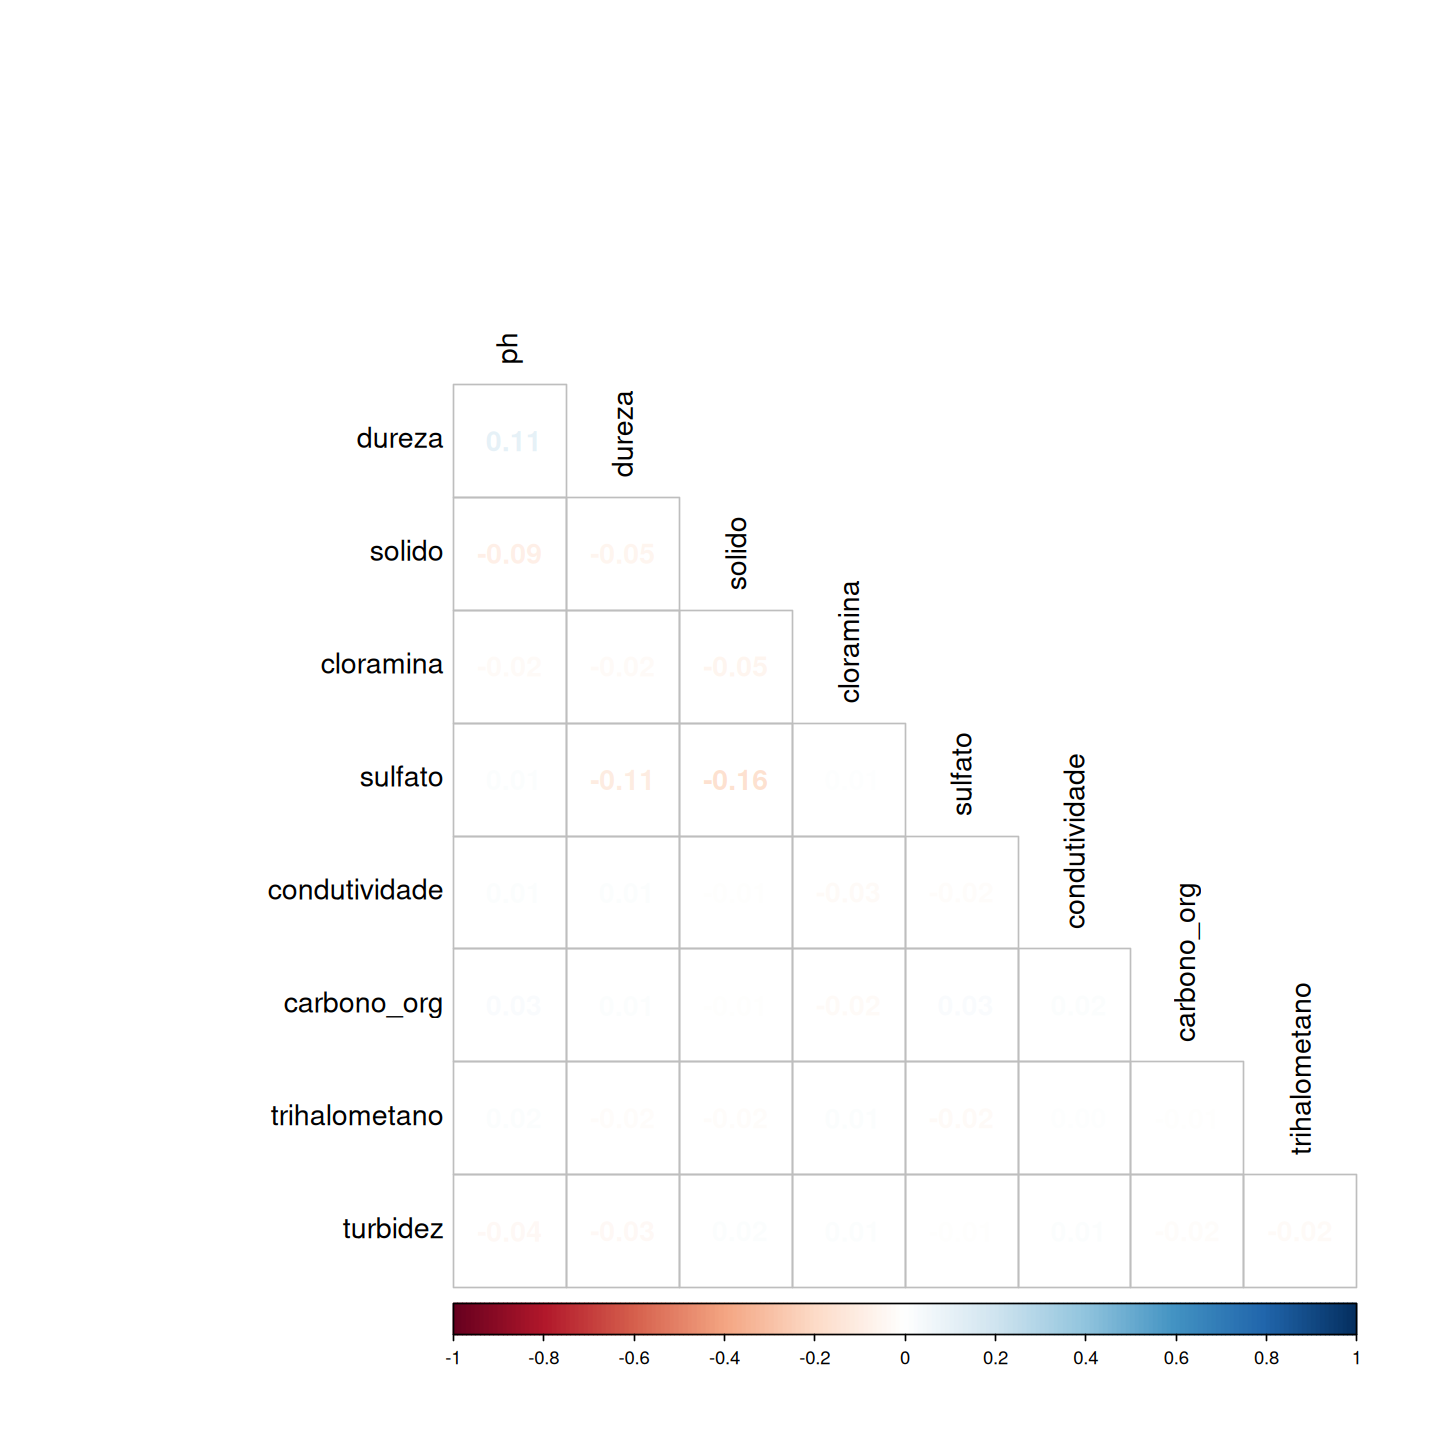

In [19]:
corrplot(cor(ag[,c(1:9)]), method='number', type='lower', diag=FALSE, 
         tl.cex=1.4, tl.col="black", cl.cex=0.9, number.cex=1.4)

Uma vez que aparentemente não há diferença de proporção de NAs nos grupos positivo e negativo, serão excluídos todos NAs.

Verificando o comportamento conjunto das variáveis para tentar uma estratégia para substituir os NAs.

|variável|nome original|descrição|
|:--|:--|:--|
|`ph`|`pH`|pH da água (0 a 14)|
|`dureza`|`Hardness`|capacidade da água precipitar sabão em mg/L|
|`solido`|`Solids`|sólido total dissolvido em ppm|
|`cloramina`|`Chloramines`|quantidade de cloramina em ppm|
|`sulfato`|`Sulfate`|quantidade de sulfatos dissolvidos em mg/L|
|`condutividade`|`Conductivity`|condutividade elétrica em µg/L|
|`carbono_org`|`Organic_carbon`|quantidade de carbono orgânico em ppm|
|`trihalometano`|`Trihalomethanes`|quantidade de trihalometanos em µg/L|
|`turbidez`|`Turbidity`|medida de propriedade de emissão de luz na água em NTU|
|`potavel`|`Potability`|indica se água é potável. 0: não é potável, 1: potável|
: Variáveis (_featurees_) {tbl-colwidths="[18,18,64]"}

In [20]:
# há dados perdidos (NAs)?
any(is.na(ag))

[1] FALSE

In [21]:
str(ag)

'data.frame':	2011 obs. of  10 variables:
 $ ph           : num  8.32 9.09 5.58 10.22 8.64 ...
 $ dureza       : num  214 181 188 248 203 ...
 $ solido       : num  22018 17979 28749 28750 13672 ...
 $ cloramina    : num  8.06 6.55 7.54 7.51 4.56 ...
 $ sulfato      : num  357 310 327 394 303 ...
 $ condutividade: num  363 398 280 284 475 ...
 $ carbono_org  : num  18.4 11.6 8.4 13.8 12.4 ...
 $ trihalometano: num  100.3 32 54.9 84.6 62.8 ...
 $ turbidez     : num  4.63 4.08 2.56 2.67 4.4 ...
 $ potavel      : int  0 0 0 0 0 0 0 0 0 0 ...


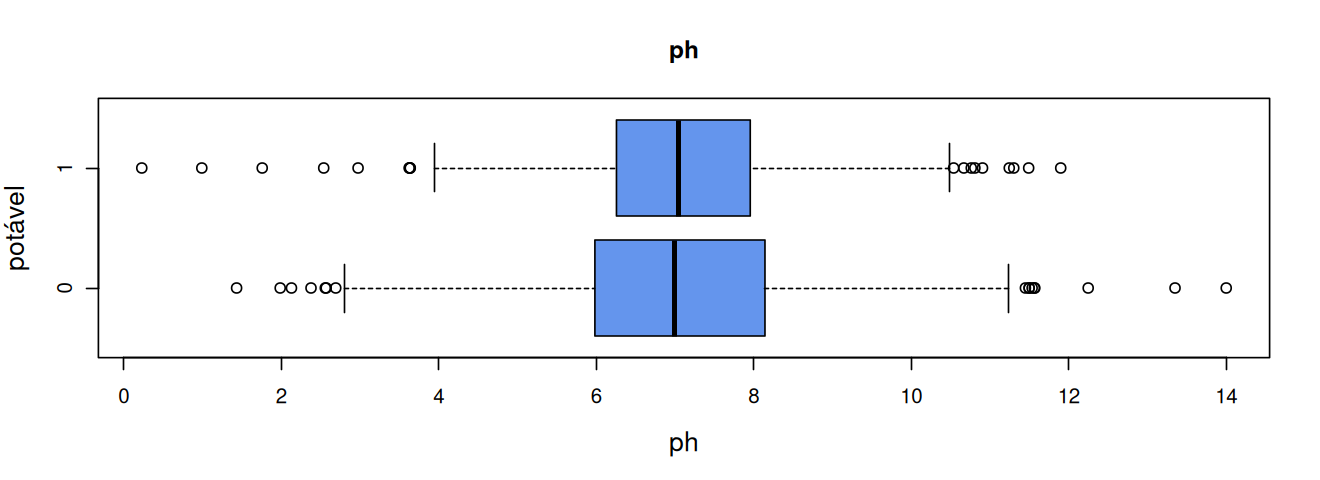

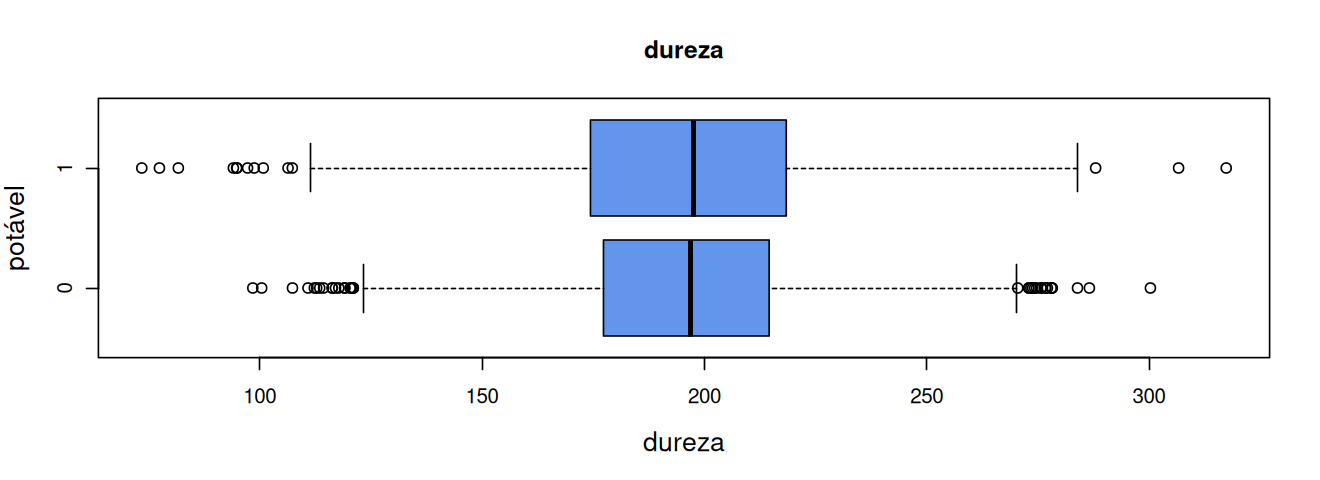

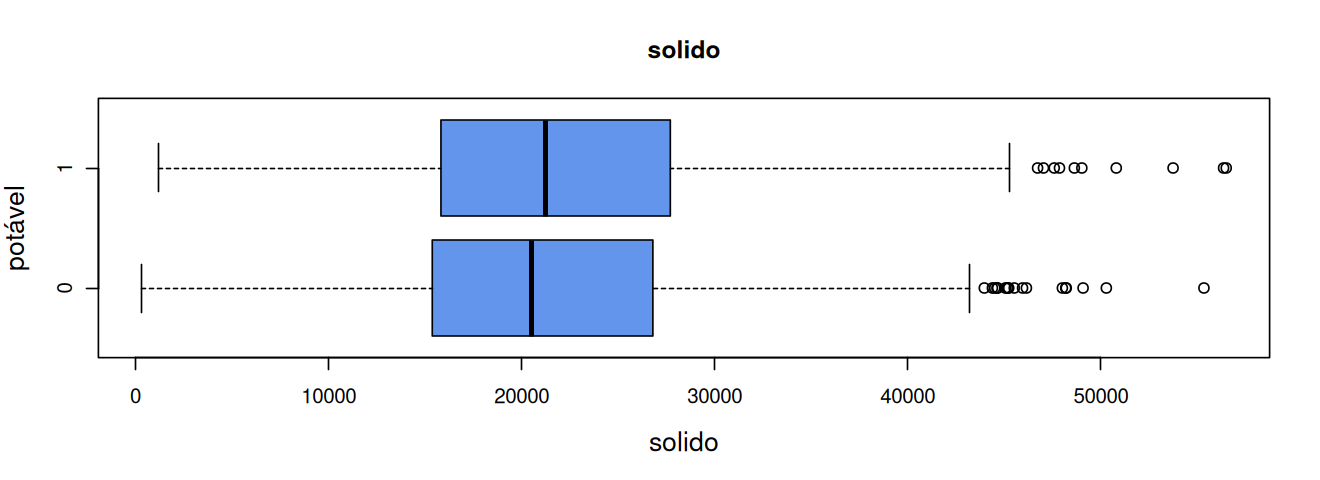

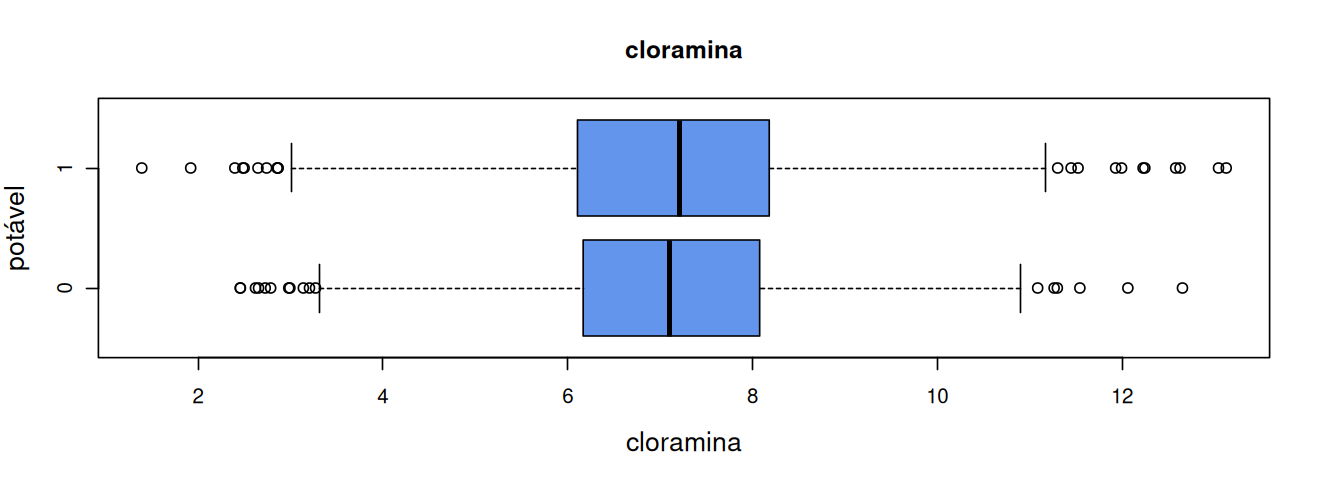

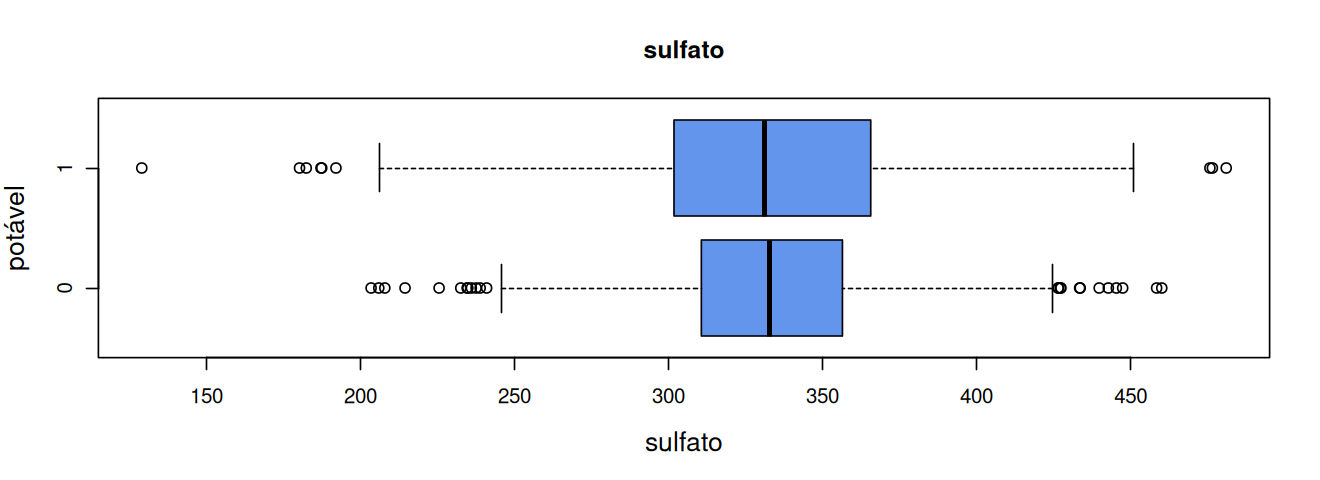

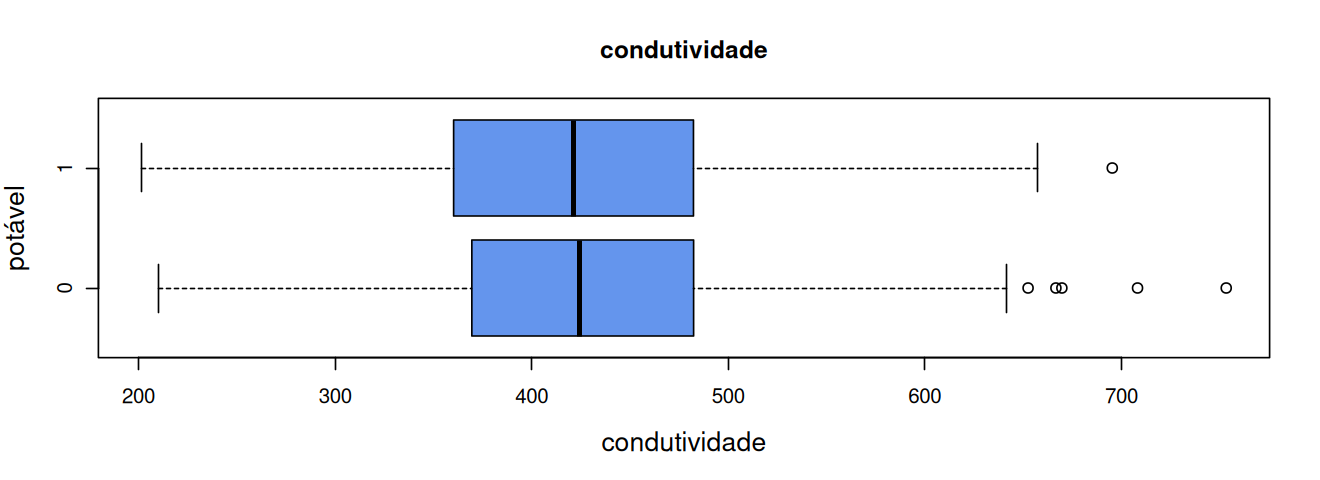

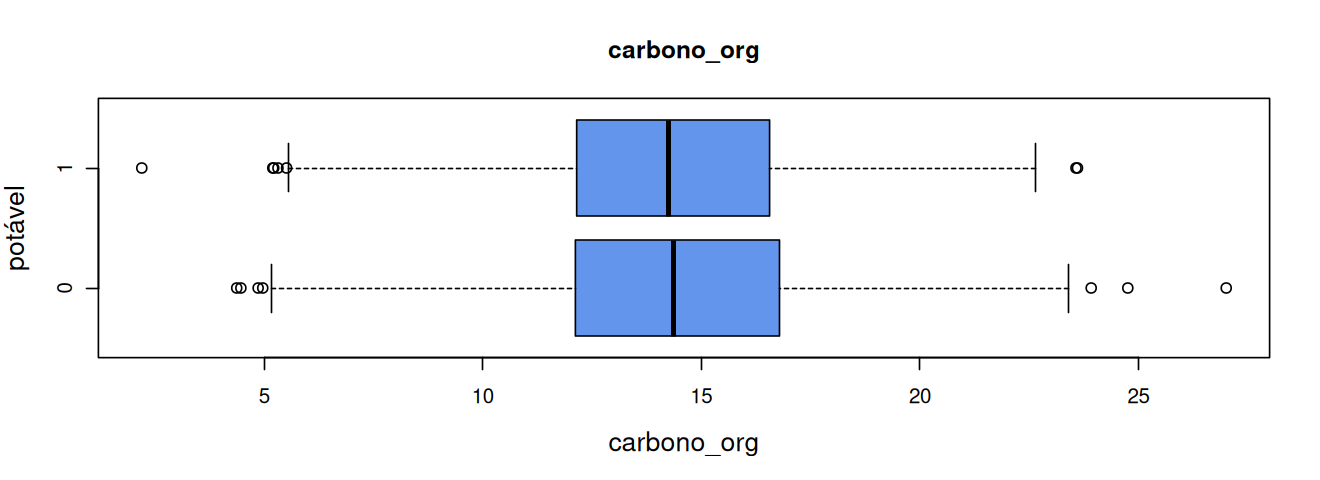

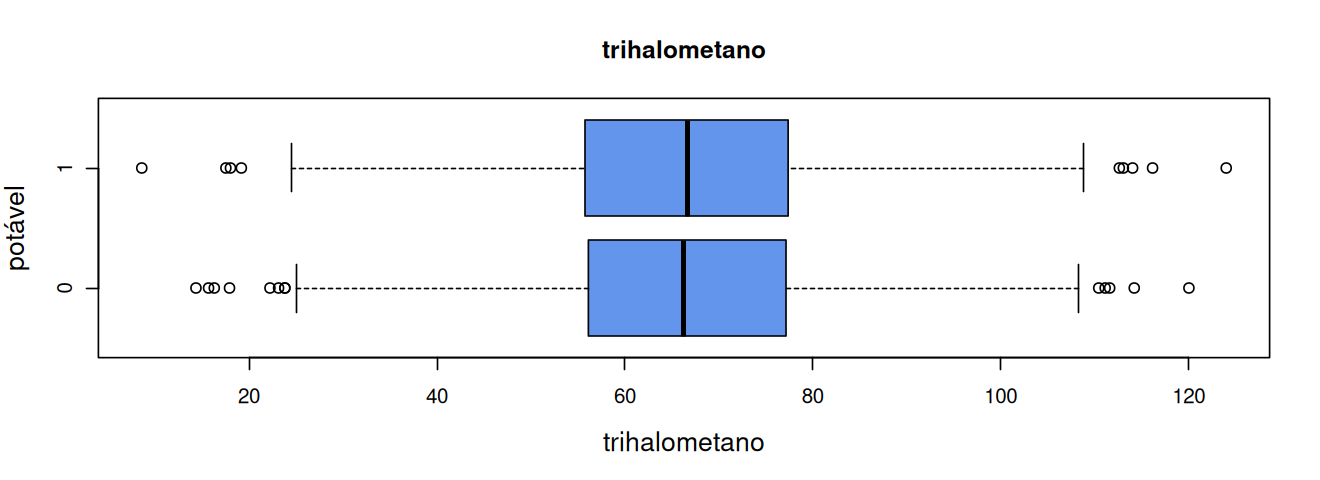

In [23]:
grafdim(11,4)
for (i in 1:8) {
    boxplot(ag[,i] ~ ag$potavel, main=names(ag)[i], 
            horizontal=TRUE, col="cornflowerblue", cex.lab=1.3, 
            xlab=names(ag)[i], ylab="potável")
}

In [24]:
nomes <- names(ag)
nomes <- nomes[-10]
nomes

[1] "ph"            "dureza"        "solido"        "cloramina"    
[5] "sulfato"       "condutividade" "carbono_org"   "trihalometano"
[9] "turbidez"

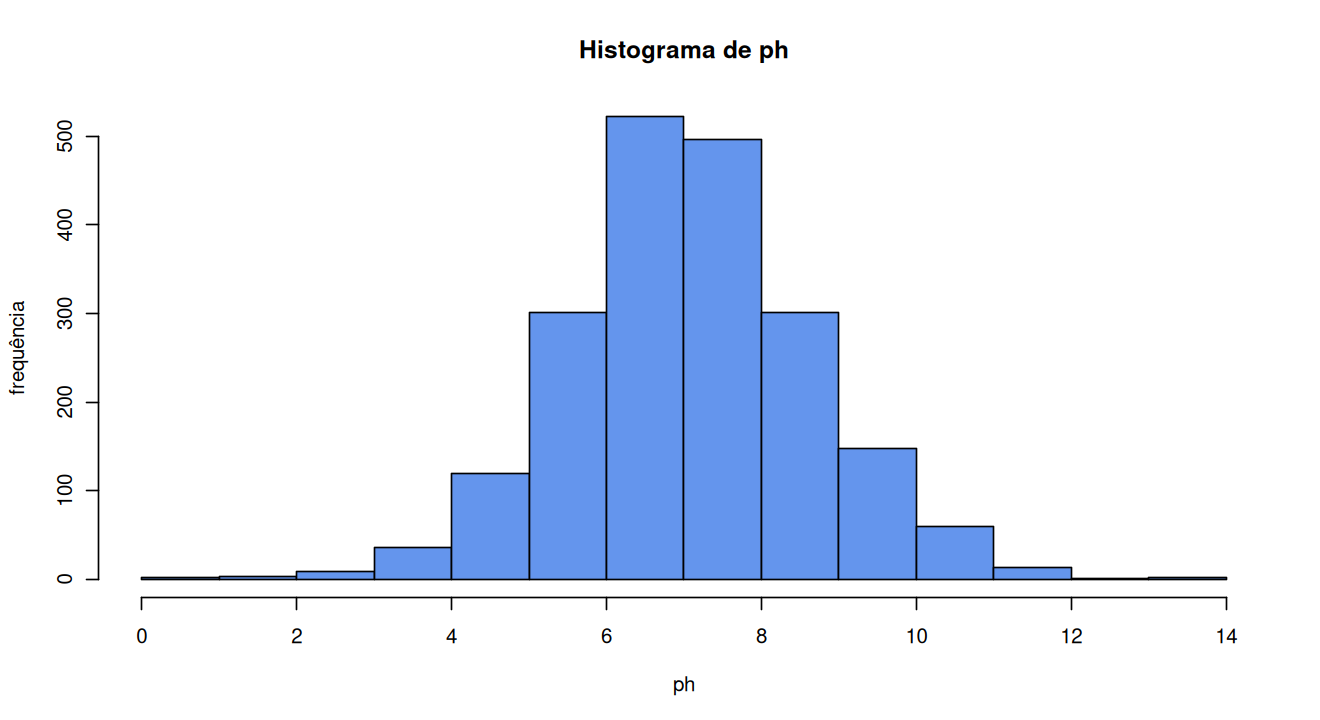

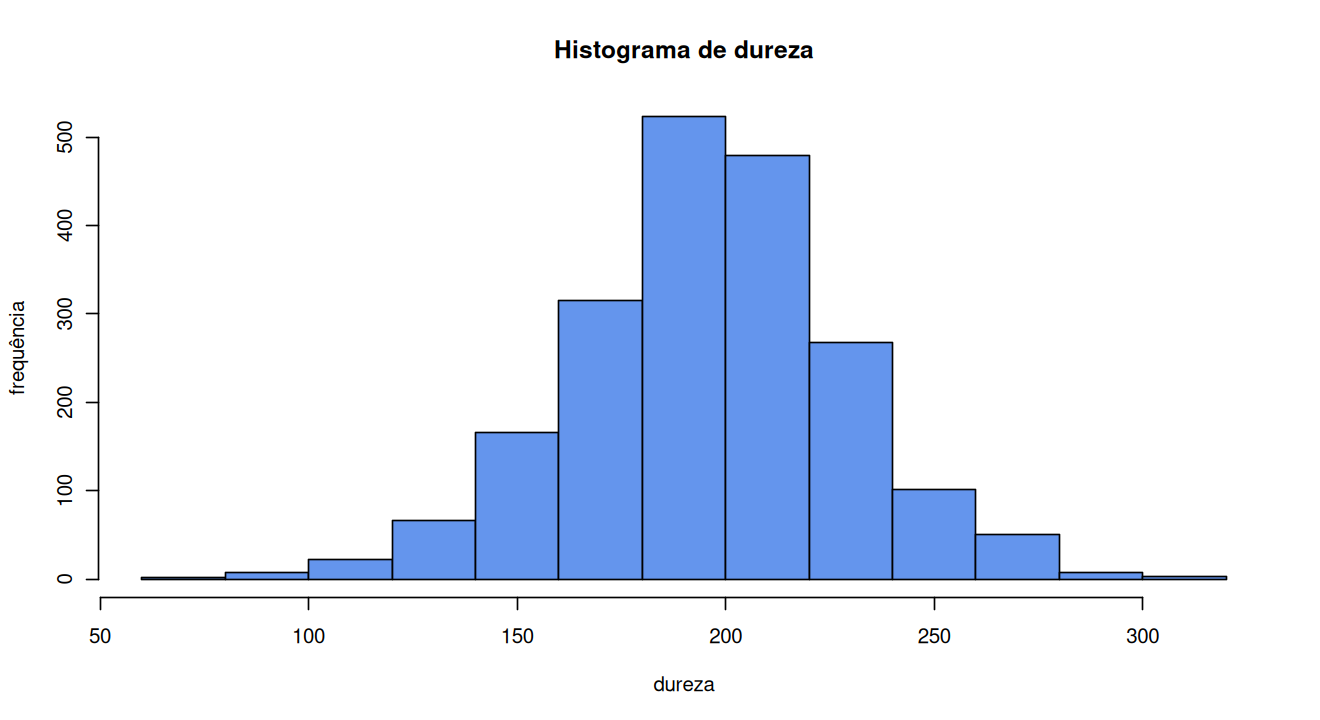

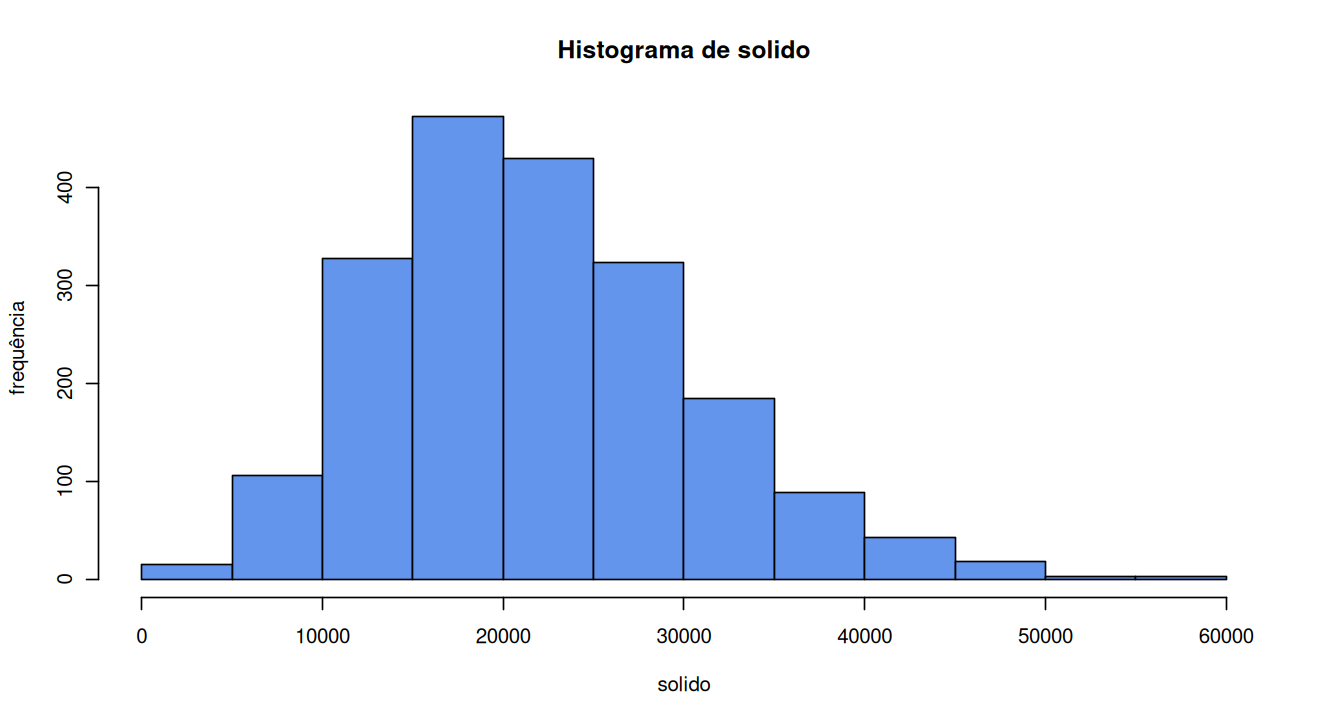

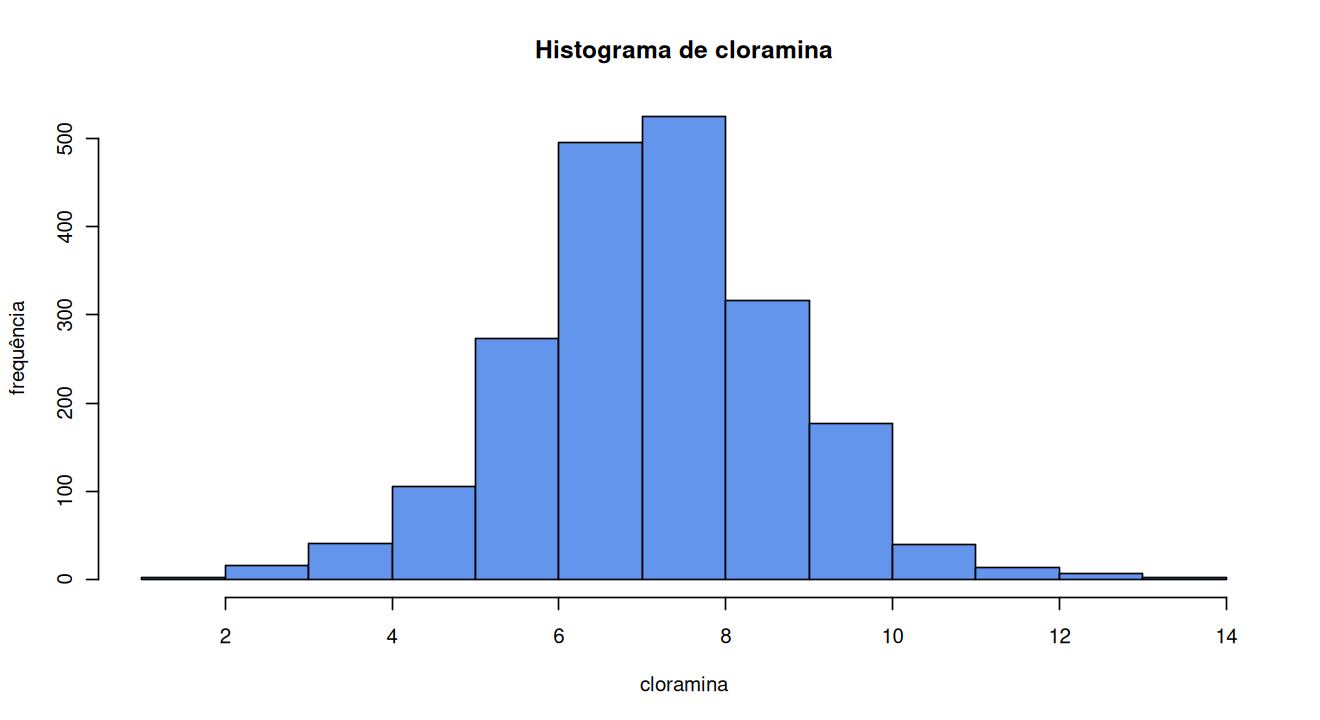

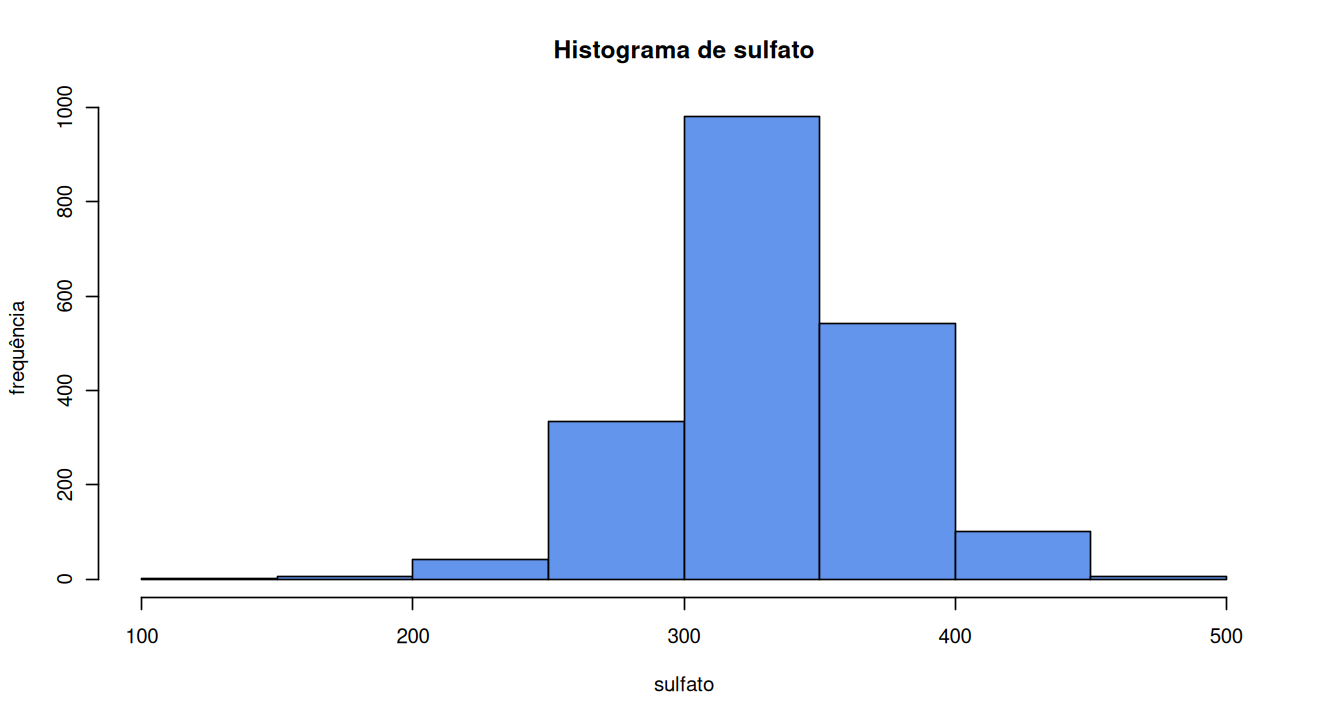

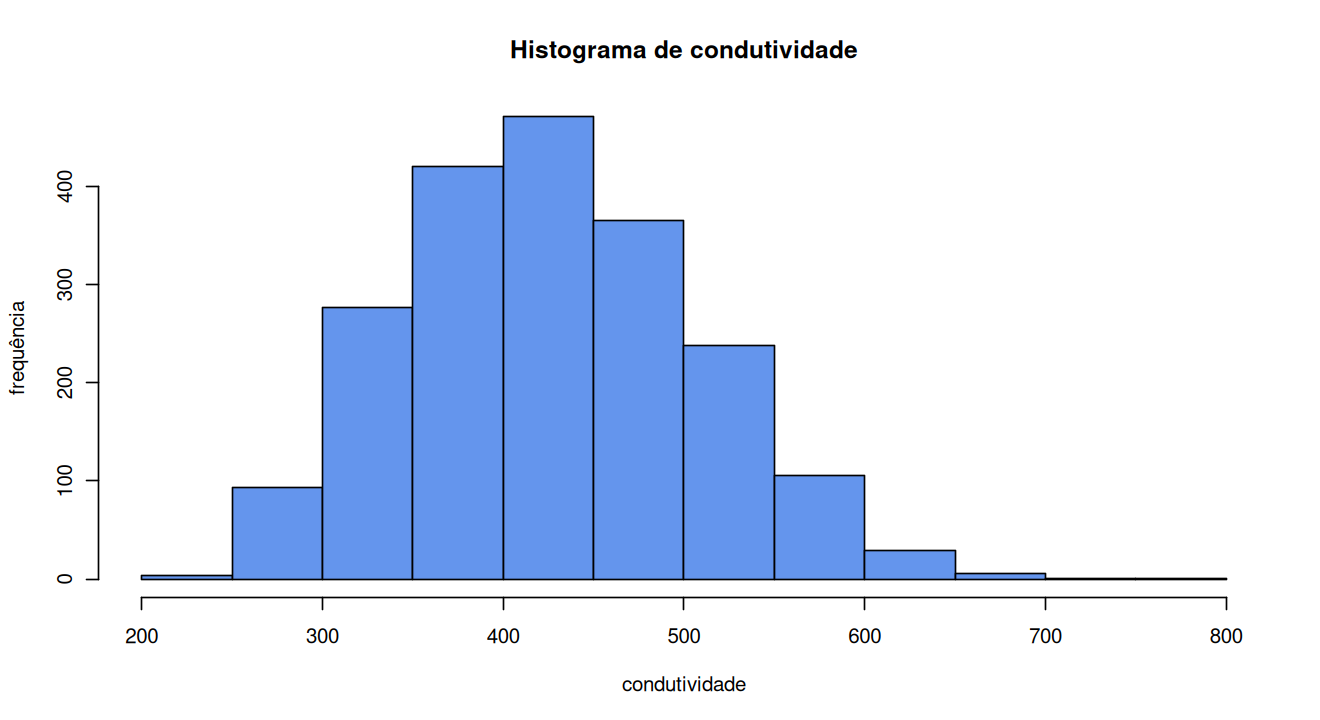

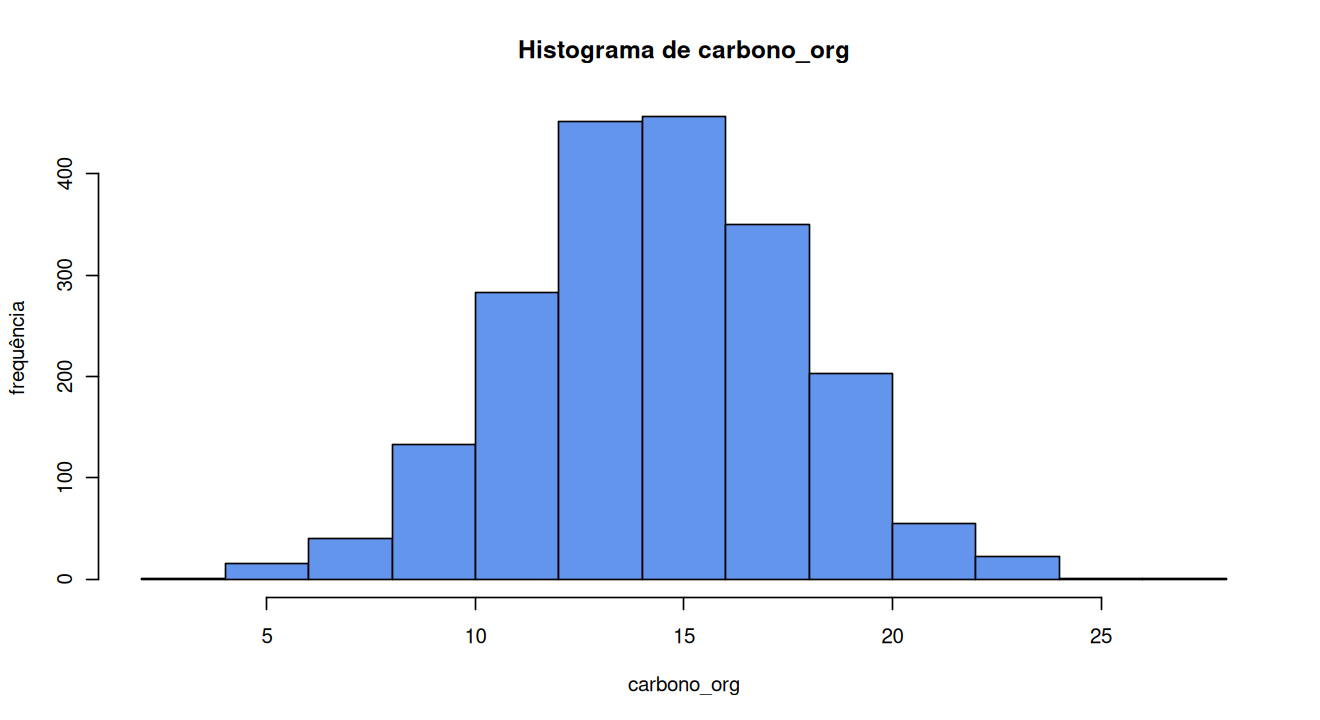

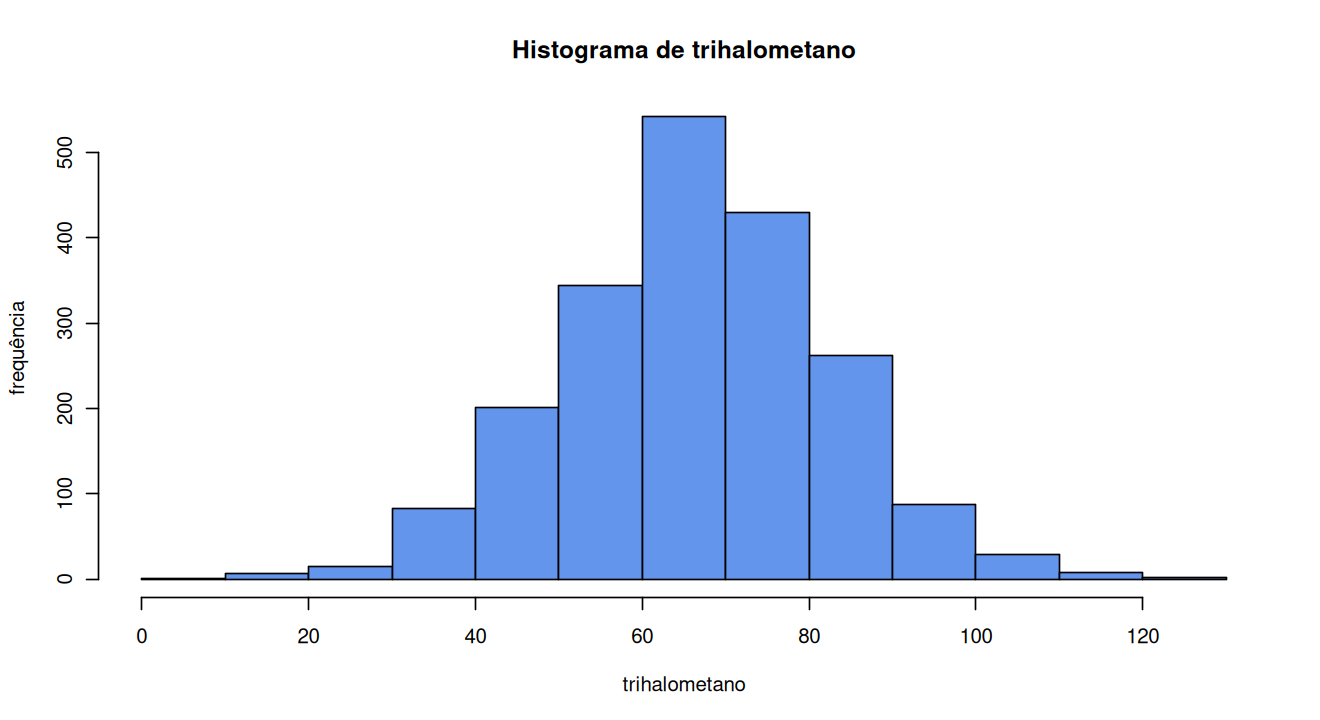

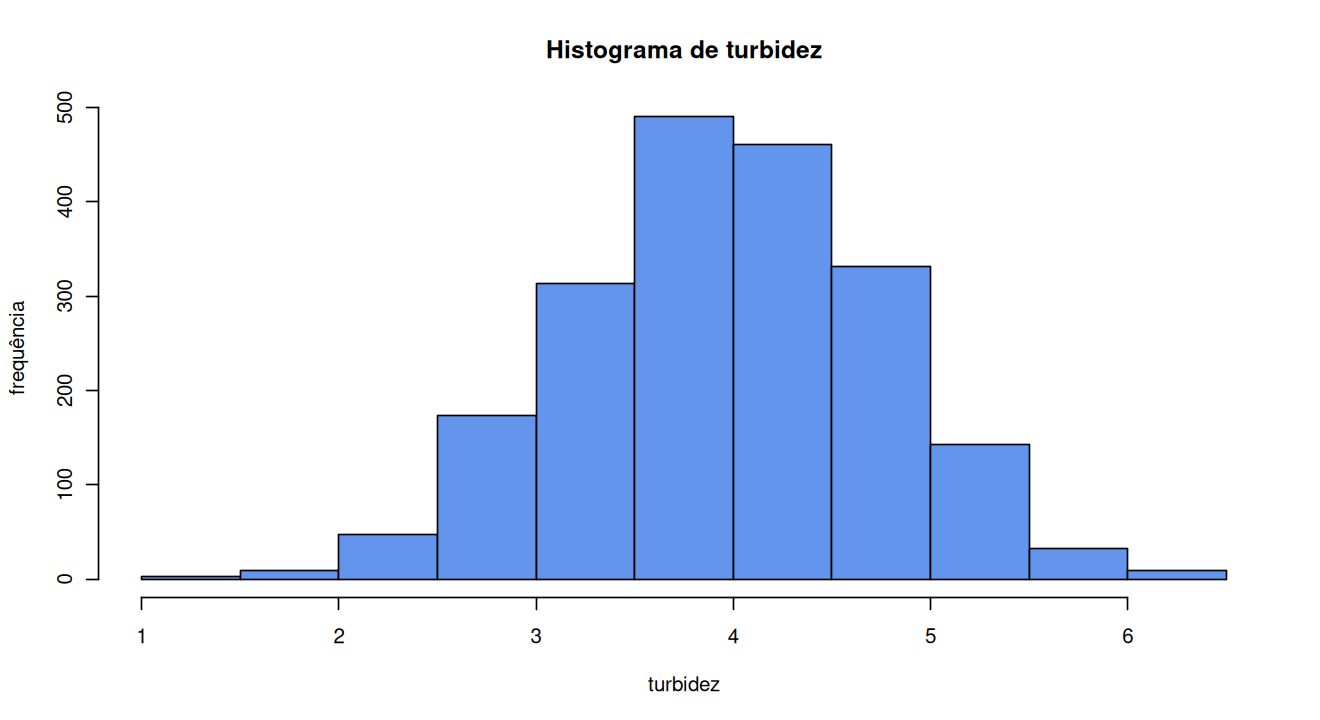

In [25]:
grafdim(11,6)
for (i in nomes) {
    hist(ag[,i], col="cornflowerblue", main=paste("Histograma de",i), 
         ylab="frequência", xlab=i)
}

In [27]:
nvariaveis <- length(nomes)
media <- numeric(nvariaveis)  
for (i in 1:nvariaveis) {
    media[i] <- mean(ag[,i])
}

In [28]:
desvio <- numeric(nvariaveis)
for (i in 1:nvariaveis) {
    desvio[i] <- sd(ag[,i])
}

Dados padronizados por ZNorm:

In [29]:
print(head(ag))

      ph dureza solido cloramina sulfato condutividade carbono_org
4   8.32    214  22018      8.06     357           363        18.4
5   9.09    181  17979      6.55     310           398        11.6
6   5.58    188  28749      7.54     327           280         8.4
7  10.22    248  28750      7.51     394           284        13.8
8   8.64    203  13672      4.56     303           475        12.4
10 11.18    227  25485      9.08     404           564        17.9
   trihalometano turbidez potavel
4          100.3     4.63       0
5           32.0     4.08       0
6           54.9     2.56       0
7           84.6     2.67       0
8           62.8     4.40       0
10          72.0     4.37       0


In [30]:
summary(ag)

       ph             dureza          solido        cloramina        sulfato   
 Min.   : 0.227   Min.   : 73.5   Min.   :  321   Min.   : 1.39   Min.   :129  
 1st Qu.: 6.090   1st Qu.:176.7   1st Qu.:15616   1st Qu.: 6.14   1st Qu.:308  
 Median : 7.027   Median :197.2   Median :20934   Median : 7.14   Median :332  
 Mean   : 7.086   Mean   :196.0   Mean   :21917   Mean   : 7.13   Mean   :333  
 3rd Qu.: 8.053   3rd Qu.:216.4   3rd Qu.:27183   3rd Qu.: 8.11   3rd Qu.:359  
 Max.   :14.000   Max.   :317.3   Max.   :56489   Max.   :13.13   Max.   :481  
 condutividade  carbono_org   trihalometano       turbidez       potavel     
 Min.   :202   Min.   : 2.2   Min.   :  8.58   Min.   :1.45   Min.   :0.000  
 1st Qu.:367   1st Qu.:12.1   1st Qu.: 55.95   1st Qu.:3.44   1st Qu.:0.000  
 Median :423   Median :14.3   Median : 66.54   Median :3.97   Median :0.000  
 Mean   :427   Mean   :14.4   Mean   : 66.40   Mean   :3.97   Mean   :0.403  
 3rd Qu.:482   3rd Qu.:16.7   3rd Qu.: 77.29   3rd

## Modelo Padrão-Base (_Baseline_ )

Vamos construir um _padrão-base_ (`baseline`) para termos um critério para saber como os modelos estão se comportando.

In [32]:
mod_base <- glm(formula = potavel ~ . , data=ag, family="binomial")  

In [33]:
summary(mod_base)


Call:
glm(formula = potavel ~ ., family = "binomial", data = ag)

Coefficients:
               Estimate Std. Error z value Pr(>|z|)  
(Intercept)   -8.76e-01   7.49e-01   -1.17    0.242  
ph             2.61e-02   2.93e-02    0.89    0.372  
dureza        -3.60e-05   1.42e-03   -0.03    0.980  
solido         9.84e-06   5.37e-06    1.83    0.067 .
cloramina      2.88e-02   2.88e-02    1.00    0.319  
sulfato       -4.11e-04   1.13e-03   -0.36    0.716  
condutividade -3.85e-04   5.66e-04   -0.68    0.496  
carbono_org   -8.91e-03   1.37e-02   -0.65    0.516  
trihalometano  1.20e-03   2.84e-03    0.42    0.673  
turbidez       5.87e-02   5.85e-02    1.00    0.315  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 2712.1  on 2010  degrees of freedom
Residual deviance: 2704.8  on 2001  degrees of freedom
AIC: 2725

Number of Fisher Scoring iterations: 4


## Análise

### Curva ROC e AUC